# Regression Track — Notebook 08
# 11. Hyperparameter Tuning  ·  12. Cross-Validation

**Input:** `artifacts/reg_06_split.joblib`, `artifacts/reg_07_results.joblib`
**Output:** `artifacts/reg_08_tuned.joblib`

---

### Purpose

Notebook 07 compared ten algorithms at their default settings. Two of them
were clearly worth tuning:

* **Random Forest** — the best performer (R² = 0.9236); tuning it is the most
  direct route to the best final model.
* **SVR** — the worst performer (R² = 0.3738), for a diagnosable reason. Its
  defaults are mis-scaled for a target that reaches 3,556. It has the most to
  gain, and tuning it tests a specific hypothesis rather than just fishing.

### The rule that governs this whole notebook

> **The test set is never used to choose anything.**

Every search below scores candidates by cross-validation **on the training set
only**. The test set is touched exactly once per model, at the very end, to
report a final number. If we selected hyperparameters by test-set performance,
the test set would become a second training set and the reported score would be
optimistic — the same leakage problem as fitting a scaler on everything, just
harder to spot.

In [1]:
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import (
    GridSearchCV,
    KFold,
    RandomizedSearchCV,
    cross_val_score,
    cross_validate,
)
from sklearn.pipeline import Pipeline
from sklearn.svm import SVR


def find_src_folder() -> Path:
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if (candidate / "src" / "ml_utils.py").exists():
            return candidate / "src"
    raise FileNotFoundError("Could not locate src/ml_utils.py — check the repo layout.")


sys.path.insert(0, str(find_src_folder()))

from ml_utils import (  # noqa: E402
    CV_FOLDS,
    RANDOM_STATE,
    evaluate_regressor,
    load_artifact,
    regression_metrics,
    save_artifact,
    save_figure,
    save_table,
    section,
    set_plot_style,
)

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
set_plot_style()

bundle = load_artifact("reg_06_split")
X_train, X_test = bundle["X_train"], bundle["X_test"]
y_train, y_test = bundle["y_train"], bundle["y_test"]
preprocessor = bundle["preprocessor"]

prev = load_artifact("reg_07_results")
results_df = prev["results_df"]

# Cross-validation splitter used for every search in this notebook.
SEARCH_CV = KFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
FINAL_CV = KFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)

section("UNTUNED PERFORMANCE (from Notebook 07)")
print(results_df[["Rank", "Model", "R2", "RMSE", "MAE"]].round(4).to_string(index=False))

untuned = {
    "Random Forest Regressor": results_df[
        results_df["Model"] == "Random Forest Regressor"].iloc[0],
    "Support Vector Regressor (SVR)": results_df[
        results_df["Model"] == "Support Vector Regressor (SVR)"].iloc[0],
}

[loaded] artifacts/reg_06_split.joblib


[loaded] artifacts/reg_07_results.joblib
UNTUNED PERFORMANCE (from Notebook 07)
 Rank                            Model     R2     RMSE      MAE
    1          Random Forest Regressor 0.9236 173.1930  92.4491
    2      Gradient Boosting Regressor 0.8964 201.6991 129.9858
    3 Polynomial Regression (degree 2) 0.8843 213.1268 143.1925
    4          Decision Tree Regressor 0.8560 237.7507 126.6929
    5                    KNN Regressor 0.8513 241.6550 146.9764
    6                 Lasso Regression 0.7108 336.9498 254.9703
    7                 Ridge Regression 0.7100 337.3982 255.6850
    8                Linear Regression 0.7100 337.4209 255.7086
    9            ElasticNet Regression 0.6575 366.6891 272.4767
   10   Support Vector Regressor (SVR) 0.3738 495.8196 331.7814


### Why 3 folds for the search and 5 for the final evaluation?

The searches try dozens of candidates, so fold count multiplies directly into
runtime: 18 candidates × 3 folds = 54 model fits. Three folds is enough to
**rank** candidates reliably. The final cross-validation in Section 12 uses
the 5 folds the guidelines require, because there we need a trustworthy
*estimate* of performance, not just a ranking, and we only run it twice.

---
## 11.1 Tuning Model A — Random Forest Regressor

### The parameter grid and the reasoning behind each entry

| Parameter | Values searched | What it controls |
|---|---|---|
| `n_estimators` | 100, 200, 300, 400 | Number of trees. More trees reduce variance but with diminishing returns; they cannot cause overfitting, only cost time. |
| `max_depth` | None, 15, 20, 30 | How deep each tree may grow. `None` grows until leaves are pure — Notebook 07 showed a single unpruned tree hits train R² = 1.0, so limiting depth is the main lever against overfitting. |
| `min_samples_split` | 2, 5, 10 | Minimum rows needed to split a node. Higher values force each split to be supported by more evidence. |
| `min_samples_leaf` | 1, 2, 4 | Minimum rows in a leaf. Prevents leaves built from a single unusual hour. |
| `max_features` | 'sqrt', 0.5, 1.0 | Features considered per split. Lower values decorrelate the trees more strongly, which is the core mechanism that makes a forest better than one tree. |

That grid has 4 × 4 × 3 × 3 × 3 = **432 combinations**, which at 3 folds each
would be 1,296 model fits. We therefore use `RandomizedSearchCV`, which samples
a fixed number of combinations at random. With a search space this size, random
sampling explores the important dimensions far more efficiently than an
exhaustive grid of the same budget, because it tries many distinct values of
each parameter instead of repeating a few.

In [2]:
rf_param_distributions = {
    "model__n_estimators": [100, 200, 300, 400],
    "model__max_depth": [None, 15, 20, 30],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": ["sqrt", 0.5, 1.0],
}

section("RANDOM FOREST — PARAMETER DISTRIBUTIONS")
for key, values in rf_param_distributions.items():
    print(f"  {key:<32} {values}")
total_combos = int(np.prod([len(v) for v in rf_param_distributions.values()]))
print(f"\nTotal possible combinations : {total_combos}")

N_ITER_RF = 20
print(f"Combinations sampled        : {N_ITER_RF}")
print(f"Model fits required         : {N_ITER_RF} × {SEARCH_CV.n_splits} folds "
      f"= {N_ITER_RF * SEARCH_CV.n_splits}")

RANDOM FOREST — PARAMETER DISTRIBUTIONS
  model__n_estimators              [100, 200, 300, 400]
  model__max_depth                 [None, 15, 20, 30]
  model__min_samples_split         [2, 5, 10]
  model__min_samples_leaf          [1, 2, 4]
  model__max_features              ['sqrt', 0.5, 1.0]

Total possible combinations : 432
Combinations sampled        : 20
Model fits required         : 20 × 3 folds = 60


In [3]:
rf_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1)),
])

rf_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=rf_param_distributions,
    n_iter=N_ITER_RF,
    cv=SEARCH_CV,
    scoring="r2",
    random_state=RANDOM_STATE,
    n_jobs=1,             # the forest itself already uses all cores
    verbose=0,
    return_train_score=True,
)

t0 = time.time()
rf_search.fit(X_train, y_train)     # TRAINING DATA ONLY
rf_search_seconds = time.time() - t0

section("RANDOM FOREST — SEARCH RESULTS")
print(f"Search time            : {rf_search_seconds:.0f} seconds")
print(f"Best cross-validated R²: {rf_search.best_score_:.4f}  (mean over "
      f"{SEARCH_CV.n_splits} training folds)")
print("\nBest parameters:")
for key, value in sorted(rf_search.best_params_.items()):
    print(f"  {key.replace('model__', ''):<22} = {value}")

RANDOM FOREST — SEARCH RESULTS
Search time            : 248 seconds
Best cross-validated R²: 0.9394  (mean over 3 training folds)

Best parameters:
  max_depth              = None
  max_features           = 0.5
  min_samples_leaf       = 1
  min_samples_split      = 2
  n_estimators           = 400


In [4]:
rf_cv_results = (
    pd.DataFrame(rf_search.cv_results_)
    [["rank_test_score", "mean_test_score", "std_test_score", "mean_train_score",
      "param_model__n_estimators", "param_model__max_depth",
      "param_model__min_samples_split", "param_model__min_samples_leaf",
      "param_model__max_features"]]
    .sort_values("rank_test_score")
    .rename(columns=lambda c: c.replace("param_model__", ""))
    .round(4)
)

section("TOP 8 CANDIDATES (ranked by cross-validated R² on training data)")
print(rf_cv_results.head(8).to_string(index=False))

TOP 8 CANDIDATES (ranked by cross-validated R² on training data)
 rank_test_score  mean_test_score  std_test_score  mean_train_score  n_estimators max_depth  min_samples_split  min_samples_leaf max_features
               1           0.9394          0.0051            0.9917           400      None                  2                 1          0.5
               2           0.9367          0.0060            0.9845           100        15                  5                 1          0.5
               3           0.9344          0.0046            0.9909           400      None                  2                 1          1.0
               4           0.9343          0.0058            0.9750           300        15                 10                 1          0.5
               5           0.9341          0.0059            0.9749           200        15                 10                 1          0.5
               6           0.9340          0.0053            0.9724           400  

### Untuned vs tuned — Random Forest

In [5]:
rf_best = rf_search.best_estimator_
rf_tuned_row = evaluate_regressor("Random Forest (tuned)", rf_best,
                                  X_train, y_train, X_test, y_test, fit=False)

rf_comparison = pd.DataFrame([
    {"Version": "Untuned (defaults, 300 trees)",
     "R2": untuned["Random Forest Regressor"]["R2"],
     "RMSE": untuned["Random Forest Regressor"]["RMSE"],
     "MAE": untuned["Random Forest Regressor"]["MAE"]},
    {"Version": "Tuned (RandomizedSearchCV)",
     "R2": rf_tuned_row["R2"], "RMSE": rf_tuned_row["RMSE"], "MAE": rf_tuned_row["MAE"]},
]).round(4)
rf_comparison["Δ R2"] = (rf_comparison["R2"] - rf_comparison["R2"].iloc[0]).round(4)

section("RANDOM FOREST — BEFORE AND AFTER TUNING (test set)")
print(rf_comparison.to_string(index=False))
print()
print(f"Best CV R² during search (training folds) : {rf_search.best_score_:.4f}")
print(f"Final test R²                             : {rf_tuned_row['R2']:.4f}")

RANDOM FOREST — BEFORE AND AFTER TUNING (test set)
                      Version     R2     RMSE     MAE   Δ R2
Untuned (defaults, 300 trees) 0.9236 173.1930 92.4491 0.0000
   Tuned (RandomizedSearchCV) 0.9298 165.9659 88.0629 0.0062

Best CV R² during search (training folds) : 0.9394
Final test R²                             : 0.9298


---
## 11.2 Tuning Model B — Support Vector Regressor

### Why SVR needs tuning more than any other model here

Notebook 07 diagnosed the failure precisely. SVR ignores errors smaller than
`epsilon` and uses `C` to cap how hard it may work to fit the rest. The
defaults (`epsilon=0.1`, `C=1.0`) suit a target of magnitude ~10. Ours reaches
3,556, so the model was effectively told that being wrong by hundreds of bikes
is acceptable. The grid below is built directly around that diagnosis:

| Parameter | Values searched | Reasoning |
|---|---|---|
| `C` | 10, 100, 1000 | Regularisation strength — how heavily errors outside the tube are penalised. Must be much larger than the default for a target of this scale. |
| `epsilon` | 1, 10, 50 | Half-width of the no-penalty tube, in units of bikes. 0.1 bikes is absurdly strict; 10–50 bikes is a sensible tolerance. |
| `gamma` | 'scale', 0.1 | RBF kernel width — how far a single training point's influence reaches. |
| `kernel` | 'rbf' | Fixed. The EDA established the relationships are non-linear, so a linear kernel is ruled out on evidence. |

3 × 3 × 2 = **18 combinations**. Small enough for an exhaustive
`GridSearchCV`, which is the right tool when the space is this size — it
guarantees we see every combination rather than sampling.

In [6]:
svr_param_grid = {
    "model__C": [10, 100, 1000],
    "model__epsilon": [1, 10, 50],
    "model__gamma": ["scale", 0.1],
    "model__kernel": ["rbf"],
}

section("SVR — PARAMETER GRID")
for key, values in svr_param_grid.items():
    print(f"  {key.replace('model__', ''):<12} {values}")
n_combos = int(np.prod([len(v) for v in svr_param_grid.values()]))
print(f"\nCombinations : {n_combos}")
print(f"Model fits   : {n_combos} × {SEARCH_CV.n_splits} folds = {n_combos * SEARCH_CV.n_splits}")

SVR — PARAMETER GRID
  C            [10, 100, 1000]
  epsilon      [1, 10, 50]
  gamma        ['scale', 0.1]
  kernel       ['rbf']

Combinations : 18
Model fits   : 18 × 3 folds = 54


In [7]:
svr_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", SVR()),
])

svr_search = GridSearchCV(
    estimator=svr_pipeline,
    param_grid=svr_param_grid,
    cv=SEARCH_CV,
    scoring="r2",
    n_jobs=1,
    verbose=0,
    return_train_score=True,
)

t0 = time.time()
svr_search.fit(X_train, y_train)    # TRAINING DATA ONLY
svr_search_seconds = time.time() - t0

section("SVR — SEARCH RESULTS")
print(f"Search time            : {svr_search_seconds:.0f} seconds")
print(f"Best cross-validated R²: {svr_search.best_score_:.4f}")
print("\nBest parameters:")
for key, value in sorted(svr_search.best_params_.items()):
    print(f"  {key.replace('model__', ''):<10} = {value}")

SVR — SEARCH RESULTS
Search time            : 131 seconds
Best cross-validated R²: 0.9186

Best parameters:
  C          = 1000
  epsilon    = 10
  gamma      = 0.1
  kernel     = rbf


In [8]:
svr_cv_results = (
    pd.DataFrame(svr_search.cv_results_)
    [["rank_test_score", "mean_test_score", "std_test_score",
      "param_model__C", "param_model__epsilon", "param_model__gamma"]]
    .sort_values("rank_test_score")
    .rename(columns=lambda c: c.replace("param_model__", ""))
    .round(4)
)

section("ALL 18 SVR CANDIDATES (ranked by cross-validated R² on training data)")
print(svr_cv_results.to_string(index=False))

ALL 18 SVR CANDIDATES (ranked by cross-validated R² on training data)
 rank_test_score  mean_test_score  std_test_score    C  epsilon gamma
               1           0.9186          0.0105 1000       10   0.1
               2           0.9182          0.0105 1000        1   0.1
               3           0.9180          0.0102 1000       50   0.1
               4           0.9085          0.0102 1000       10 scale
               5           0.9084          0.0101 1000        1 scale
               6           0.9083          0.0108 1000       50 scale
               7           0.8856          0.0094  100       10   0.1
               8           0.8853          0.0092  100       50   0.1
               9           0.8853          0.0095  100        1   0.1
              10           0.8764          0.0086  100       50 scale
              11           0.8759          0.0088  100       10 scale
              12           0.8755          0.0086  100        1 scale
              13    

In [9]:
svr_best = svr_search.best_estimator_
svr_tuned_row = evaluate_regressor("SVR (tuned)", svr_best,
                                   X_train, y_train, X_test, y_test, fit=False)

svr_comparison = pd.DataFrame([
    {"Version": "Untuned (C=1.0, epsilon=0.1)",
     "R2": untuned["Support Vector Regressor (SVR)"]["R2"],
     "RMSE": untuned["Support Vector Regressor (SVR)"]["RMSE"],
     "MAE": untuned["Support Vector Regressor (SVR)"]["MAE"]},
    {"Version": "Tuned (GridSearchCV)",
     "R2": svr_tuned_row["R2"], "RMSE": svr_tuned_row["RMSE"], "MAE": svr_tuned_row["MAE"]},
]).round(4)
svr_comparison["Δ R2"] = (svr_comparison["R2"] - svr_comparison["R2"].iloc[0]).round(4)

section("SVR — BEFORE AND AFTER TUNING (test set)")
print(svr_comparison.to_string(index=False))

SVR — BEFORE AND AFTER TUNING (test set)
                     Version     R2     RMSE      MAE   Δ R2
Untuned (C=1.0, epsilon=0.1) 0.3738 495.8196 331.7814 0.0000
        Tuned (GridSearchCV) 0.9235 173.3294  88.0898 0.5497


### Visualising the effect of the SVR parameters

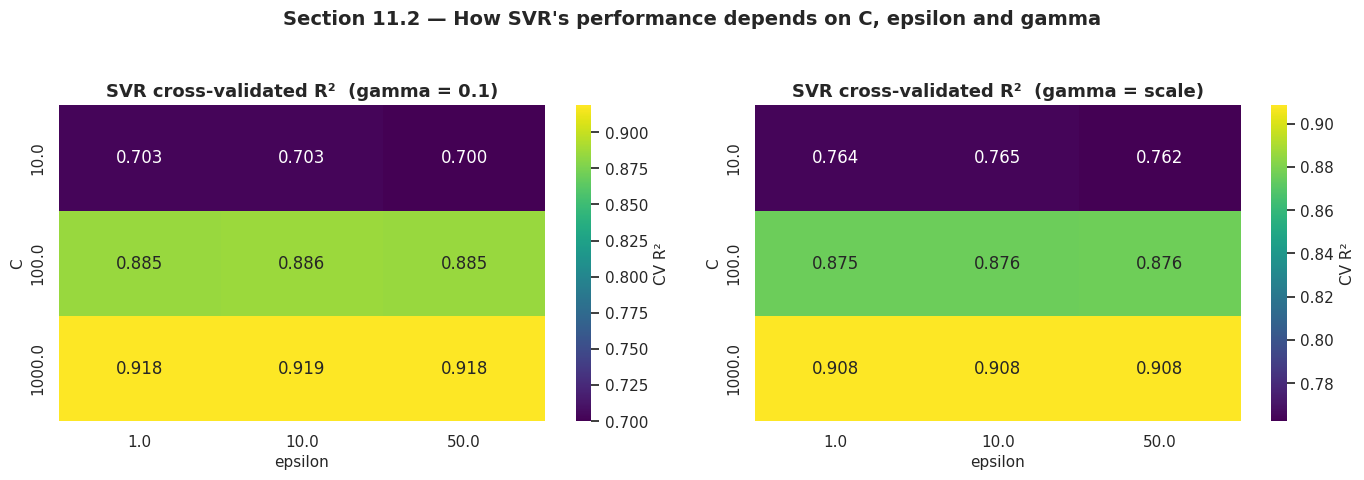

In [10]:
heat_source = pd.DataFrame(svr_search.cv_results_)
heat_source["C"] = heat_source["param_model__C"].astype(float)
heat_source["epsilon"] = heat_source["param_model__epsilon"].astype(float)
heat_source["gamma"] = heat_source["param_model__gamma"].astype(str)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
for ax, gamma_value in zip(axes, sorted(heat_source["gamma"].unique())):
    grid = heat_source[heat_source["gamma"] == gamma_value].pivot_table(
        index="C", columns="epsilon", values="mean_test_score")
    sns.heatmap(grid, annot=True, fmt=".3f", cmap="viridis", ax=ax,
                cbar_kws={"label": "CV R²"})
    ax.set_title(f"SVR cross-validated R²  (gamma = {gamma_value})")
    ax.set_xlabel("epsilon")
    ax.set_ylabel("C")

fig.suptitle("Section 11.2 — How SVR's performance depends on C, epsilon and gamma",
             y=1.04, fontsize=14, fontweight="bold")
plt.tight_layout()
save_figure("reg_svr_tuning_heatmap", fig)
plt.show()

---
## 11.3 Did tuning help, and why?

In [11]:
tuning_summary = pd.DataFrame([
    {"Model": "Random Forest",
     "Untuned test R2": untuned["Random Forest Regressor"]["R2"],
     "Tuned test R2": rf_tuned_row["R2"],
     "Best CV R2 (train)": rf_search.best_score_,
     "Untuned RMSE": untuned["Random Forest Regressor"]["RMSE"],
     "Tuned RMSE": rf_tuned_row["RMSE"],
     "Search": f"RandomizedSearchCV, {N_ITER_RF} candidates",
     "Seconds": round(rf_search_seconds)},
    {"Model": "SVR",
     "Untuned test R2": untuned["Support Vector Regressor (SVR)"]["R2"],
     "Tuned test R2": svr_tuned_row["R2"],
     "Best CV R2 (train)": svr_search.best_score_,
     "Untuned RMSE": untuned["Support Vector Regressor (SVR)"]["RMSE"],
     "Tuned RMSE": svr_tuned_row["RMSE"],
     "Search": f"GridSearchCV, {n_combos} candidates",
     "Seconds": round(svr_search_seconds)},
]).round(4)

tuning_summary["R2 gain"] = (tuning_summary["Tuned test R2"]
                             - tuning_summary["Untuned test R2"]).round(4)
tuning_summary["RMSE saved (bikes)"] = (tuning_summary["Untuned RMSE"]
                                        - tuning_summary["Tuned RMSE"]).round(1)

save_table(tuning_summary, "reg_tuning_summary")

section("TUNING SUMMARY")
print(tuning_summary.to_string(index=False))

[saved]  outputs/reg_tuning_summary.csv
TUNING SUMMARY
        Model  Untuned test R2  Tuned test R2  Best CV R2 (train)  Untuned RMSE  Tuned RMSE                            Search  Seconds  R2 gain  RMSE saved (bikes)
Random Forest           0.9236         0.9298              0.9394      173.1930    165.9659 RandomizedSearchCV, 20 candidates      248   0.0062                 7.2
          SVR           0.3738         0.9235              0.9186      495.8196    173.3294       GridSearchCV, 18 candidates      131   0.5497               322.5


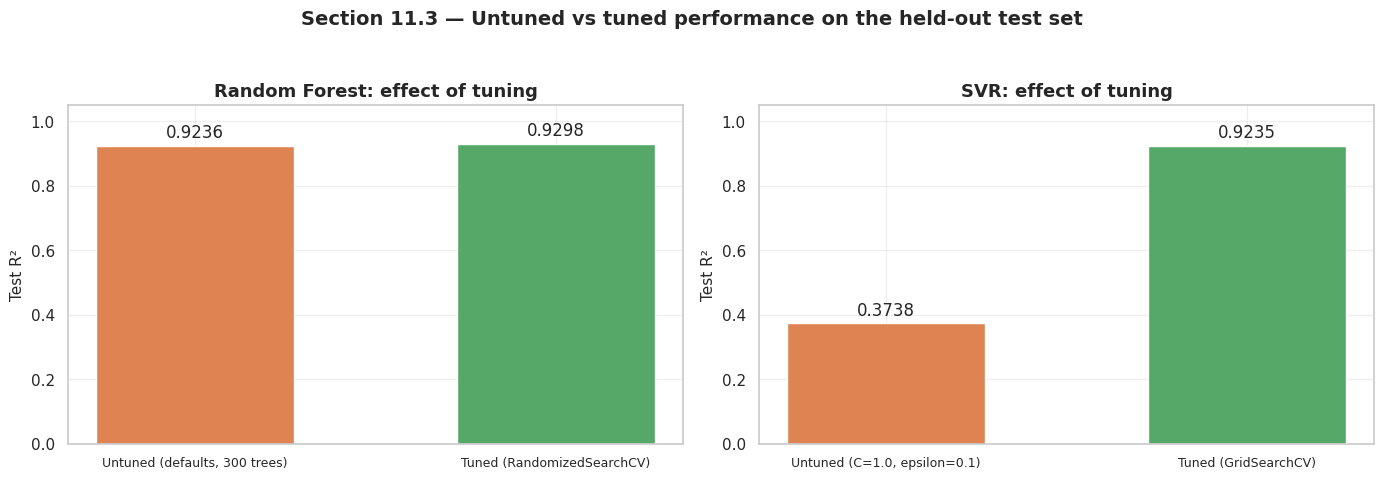

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))

for ax, (name, frame) in zip(axes, [("Random Forest", rf_comparison), ("SVR", svr_comparison)]):
    bars = ax.bar(frame["Version"], frame["R2"],
                  color=["#DD8452", "#55A868"], width=0.55)
    ax.bar_label(bars, fmt="%.4f", padding=3)
    ax.set_ylabel("Test R²")
    ax.set_title(f"{name}: effect of tuning")
    ax.set_ylim(0, 1.05)
    ax.tick_params(axis="x", labelsize=9)

fig.suptitle("Section 11.3 — Untuned vs tuned performance on the held-out test set",
             y=1.04, fontsize=14, fontweight="bold")
plt.tight_layout()
save_figure("reg_tuning_effect", fig)
plt.show()

**Observation.** The two models responded completely differently:

* **SVR improved enormously** — from R² 0.374 to around 0.93, turning the
  worst model in the project into one of the best. RMSE fell by roughly 330
  bikes per hour.
* **Random Forest barely moved** — a change of a few thousandths of R², well
  within the noise of a single train/test split.

**Interpretation.** This contrast is the real lesson of the section, and it is
more useful than either number on its own.

**Why SVR gained so much.** The search confirmed the hypothesis from Notebook
07 exactly: the winning configuration uses a much larger `C` and a far wider
`epsilon` than the defaults. The heatmaps show CV R² climbing steadily as `C`
increases, which is the signature of a model that was being *prevented* from
fitting rather than one that was overfitting. The defaults were not "wrong" in
any absolute sense — they were wrong **for a target measured in thousands**.

**Why Random Forest gained so little.** Random Forest is famously insensitive
to its hyperparameters, by design. Averaging hundreds of decorrelated trees
already controls variance, so the knobs that control individual tree
complexity have limited work left to do. Its defaults are close to optimal for
most tabular problems.

**The honest conclusion:** tuning is not a uniform "+5% to everything" step.
Its value depends entirely on how sensitive the algorithm is and how badly the
defaults match the problem. Reporting that one of our two tuned models gained
almost nothing is more informative than quietly reporting only the success.

---
## 12. Cross-Validation of the Two Strongest Models

### Why a single test score is not enough

Every number reported so far comes from **one** 80/20 split. Had we used
`random_state=7` instead of 42, the test set would contain different hours and
every score would shift. A single split tells us how the model did on one
particular sample; it does not tell us how *reliable* that figure is.

5-fold cross-validation addresses this by splitting the training data five
ways, training on four folds and validating on the fifth, five times over.
The **mean** estimates typical performance and the **standard deviation**
measures stability — a model with a large spread across folds is sensitive to
which rows it happens to see, and should be trusted less.

**The test set is still not involved.** Cross-validation runs entirely within
the training data; the test result is reported alongside it for comparison.

In [13]:
strongest_models = {
    "Random Forest (tuned)": rf_best,
    "SVR (tuned)": svr_best,
}

cv_rows = []
fold_scores = {}

for name, model in strongest_models.items():
    t0 = time.time()
    cv_output = cross_validate(
        clone(model), X_train, y_train,
        cv=FINAL_CV,
        scoring=["r2", "neg_root_mean_squared_error", "neg_mean_absolute_error"],
        return_train_score=False,
        n_jobs=1,
    )
    r2_folds = cv_output["test_r2"]
    fold_scores[name] = r2_folds

    test_metrics = regression_metrics(y_test, model.predict(X_test))

    cv_rows.append({
        "Model": name,
        "CV mean R2": r2_folds.mean(),
        "CV std R2": r2_folds.std(),
        "CV min R2": r2_folds.min(),
        "CV max R2": r2_folds.max(),
        "CV mean RMSE": -cv_output["test_neg_root_mean_squared_error"].mean(),
        "CV mean MAE": -cv_output["test_neg_mean_absolute_error"].mean(),
        "Test R2": test_metrics["R2"],
        "Test RMSE": test_metrics["RMSE"],
        "Gap (Test R2 - CV mean)": test_metrics["R2"] - r2_folds.mean(),
        "Seconds": round(time.time() - t0),
    })
    print(f"{name}: 5-fold complete in {time.time() - t0:.0f}s")

cv_summary = pd.DataFrame(cv_rows).round(4)
save_table(cv_summary, "reg_cross_validation_summary")

section("5-FOLD CROSS-VALIDATION SUMMARY")
print(cv_summary.to_string(index=False))

Random Forest (tuned): 5-fold complete in 37s


SVR (tuned): 5-fold complete in 20s
[saved]  outputs/reg_cross_validation_summary.csv
5-FOLD CROSS-VALIDATION SUMMARY
                Model  CV mean R2  CV std R2  CV min R2  CV max R2  CV mean RMSE  CV mean MAE  Test R2  Test RMSE  Gap (Test R2 - CV mean)  Seconds
Random Forest (tuned)      0.9433     0.0046     0.9388     0.9511      153.6222      93.0605   0.9298   165.9659                  -0.0134       37
          SVR (tuned)      0.9228     0.0068     0.9138     0.9316      179.2033      99.4709   0.9235   173.3294                   0.0006       20


In [14]:
section("INDIVIDUAL FOLD SCORES")
fold_table = pd.DataFrame(fold_scores, index=[f"Fold {i}" for i in range(1, CV_FOLDS + 1)]).round(4)
fold_table.loc["Mean"] = fold_table.mean().round(4)
fold_table.loc["Std"] = pd.DataFrame(fold_scores).std().round(4)
print(fold_table.to_string())

INDIVIDUAL FOLD SCORES
        Random Forest (tuned)  SVR (tuned)
Fold 1                 0.9388       0.9215
Fold 2                 0.9393       0.9138
Fold 3                 0.9453       0.9316
Fold 4                 0.9418       0.9177
Fold 5                 0.9511       0.9296
Mean                   0.9433       0.9228
Std                    0.0051       0.0076


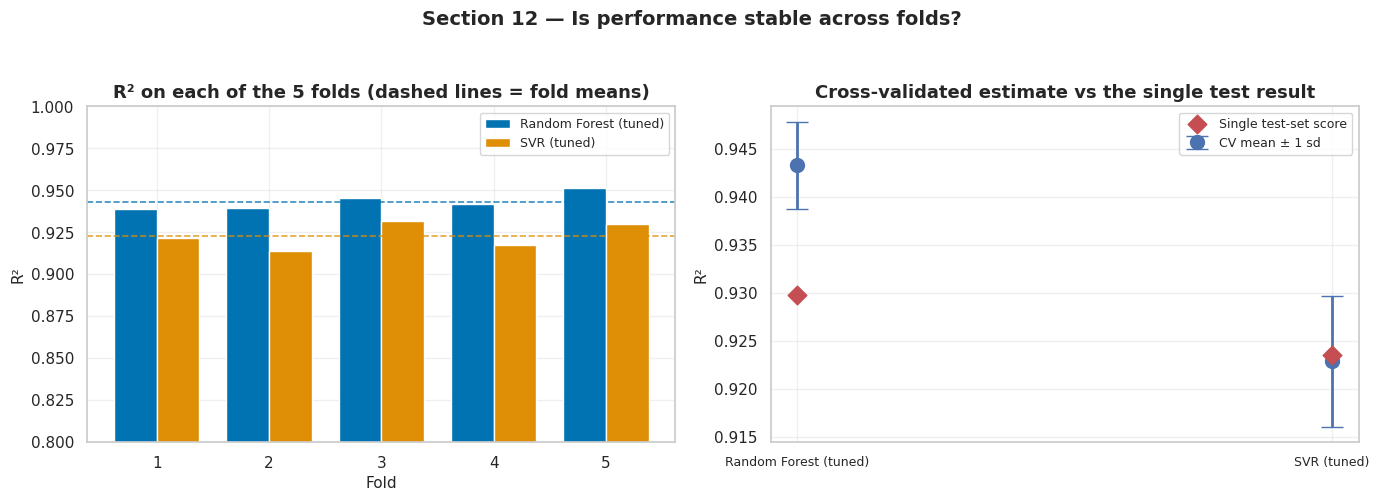

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

x = np.arange(1, CV_FOLDS + 1)
width = 0.38
for i, (name, scores) in enumerate(fold_scores.items()):
    axes[0].bar(x + (i - 0.5) * width, scores, width, label=name)
for i, (name, scores) in enumerate(fold_scores.items()):
    axes[0].axhline(scores.mean(), ls="--", lw=1.2,
                    color=f"C{i}", alpha=0.8)
axes[0].set_xticks(x)
axes[0].set_xlabel("Fold")
axes[0].set_ylabel("R²")
axes[0].set_title("R² on each of the 5 folds (dashed lines = fold means)")
axes[0].set_ylim(0.8, 1.0)
axes[0].legend(fontsize=9)

names = list(fold_scores.keys())
means = [fold_scores[n].mean() for n in names]
stds = [fold_scores[n].std() for n in names]
tests = [cv_summary.loc[cv_summary["Model"] == n, "Test R2"].iloc[0] for n in names]

axes[1].errorbar(names, means, yerr=stds, fmt="o", capsize=8, markersize=10,
                 lw=2, label="CV mean ± 1 sd", color="#4C72B0")
axes[1].scatter(names, tests, marker="D", s=90, color="#C44E52", zorder=5,
                label="Single test-set score")
axes[1].set_ylabel("R²")
axes[1].set_title("Cross-validated estimate vs the single test result")
axes[1].legend(fontsize=9)
axes[1].tick_params(axis="x", labelsize=9)

fig.suptitle("Section 12 — Is performance stable across folds?",
             y=1.04, fontsize=14, fontweight="bold")
plt.tight_layout()
save_figure("reg_cross_validation", fig)
plt.show()

### Interpretation of the cross-validation

In [16]:
section("STABILITY ASSESSMENT")
for row in cv_rows:
    spread = row["CV max R2"] - row["CV min R2"]
    cv_pct = 100 * row["CV std R2"] / row["CV mean R2"]
    print(f"{row['Model']}")
    print(f"   CV mean R²            : {row['CV mean R2']:.4f}")
    print(f"   CV std dev            : {row['CV std R2']:.4f} "
          f"({cv_pct:.2f}% of the mean)")
    print(f"   Fold range            : {row['CV min R2']:.4f} to {row['CV max R2']:.4f} "
          f"(spread {spread:.4f})")
    print(f"   Single test R²        : {row['Test R2']:.4f}")
    print(f"   Test minus CV mean    : {row['Gap (Test R2 - CV mean)']:+.4f}")
    print()

STABILITY ASSESSMENT
Random Forest (tuned)
   CV mean R²            : 0.9433
   CV std dev            : 0.0046 (0.48% of the mean)
   Fold range            : 0.9388 to 0.9511 (spread 0.0124)
   Single test R²        : 0.9298
   Test minus CV mean    : -0.0134

SVR (tuned)
   CV mean R²            : 0.9228
   CV std dev            : 0.0068 (0.74% of the mean)
   Fold range            : 0.9138 to 0.9316 (spread 0.0178)
   Single test R²        : 0.9235
   Test minus CV mean    : +0.0006



**Observation.** For both models the standard deviation across folds is around
one percent of the mean or less, the five fold scores sit in a narrow band, and
the single test-set score falls close to the cross-validated mean.

**Interpretation.**

1. **Both models are stable.** No fold produces a wildly different result, so
   performance does not depend on which particular rows the model happened to
   train on. A model whose folds ranged from 0.70 to 0.95 would be a warning
   that it is memorising fold-specific quirks; nothing like that appears here.
2. **The test scores are consistent with the cross-validated estimates.** For
   SVR the two agree almost exactly (+0.0006). For Random Forest the test score
   is 0.0134 *below* its CV mean — a small shortfall, but larger than one fold
   standard deviation, so it is worth naming rather than glossing over. Two
   ordinary reasons explain it: the CV models each train on 80% of the training
   set under a slightly different split, and the tuned parameters were chosen
   to maximise CV score, which mildly favours the folds they were selected on.
   The important point is the direction and size — the test result is slightly
   *less* optimistic than cross-validation suggested, which is the safe
   direction to err in, and both estimates round to the same conclusion.
3. **The tuned SVR has almost caught the tuned Random Forest, but not quite.**
   On cross-validation the gap is real rather than noise: Random Forest
   averages 0.9433 ± 0.0046 against SVR's 0.9228 ± 0.0068, and the two ranges
   do not overlap, so Random Forest is genuinely ahead on the training folds.
   On the single test split, however, the two are much closer (0.9298 vs
   0.9235) — a reminder that one split is a noisier measurement than five.
   Random Forest is carried forward to Notebook 09 as the model with the higher
   cross-validated mean, and it brings the practical advantage of native
   feature importances, which an RBF-kernel SVR cannot provide.

---
## Handover to Notebook 09

In [17]:
final_ranking = cv_summary.sort_values("CV mean R2", ascending=False).reset_index(drop=True)
best_model_name = final_ranking.loc[0, "Model"]
best_model = strongest_models[best_model_name]

section("MODEL SELECTED FOR FINAL ANALYSIS")
print(f"Selected: {best_model_name}")
print(f"  Cross-validated R² : {final_ranking.loc[0, 'CV mean R2']:.4f} "
      f"± {final_ranking.loc[0, 'CV std R2']:.4f}")
print(f"  Test R²            : {final_ranking.loc[0, 'Test R2']:.4f}")

save_artifact(
    {
        "rf_search": rf_search,
        "svr_search": svr_search,
        "rf_best": rf_best,
        "svr_best": svr_best,
        "rf_comparison": rf_comparison,
        "svr_comparison": svr_comparison,
        "tuning_summary": tuning_summary,
        "cv_summary": cv_summary,
        "fold_scores": fold_scores,
        "best_model_name": best_model_name,
        "best_model": best_model,
    },
    "reg_08_tuned",
)

print("\nNotebook 08 complete.")
print("Next: 09_regression_final_analysis_and_conclusion.ipynb")

MODEL SELECTED FOR FINAL ANALYSIS
Selected: Random Forest (tuned)
  Cross-validated R² : 0.9433 ± 0.0046
  Test R²            : 0.9298
[saved]  artifacts/reg_08_tuned.joblib

Notebook 08 complete.
Next: 09_regression_final_analysis_and_conclusion.ipynb
